In [1]:
from qiskit import QuantumCircuit

# Part A: Correlated outcomes
qc_A = QuantumCircuit(2, 2)

qc_A.h(0)
qc_A.cx(0, 1)

qc_A.measure([0, 1], [0, 1])

print(qc_A.draw())

     ┌───┐     ┌─┐   
q_0: ┤ H ├──■──┤M├───
     └───┘┌─┴─┐└╥┘┌─┐
q_1: ─────┤ X ├─╫─┤M├
          └───┘ ║ └╥┘
c: 2/═══════════╩══╩═
                0  1 


Part A results: {'00': 54, '11': 46}


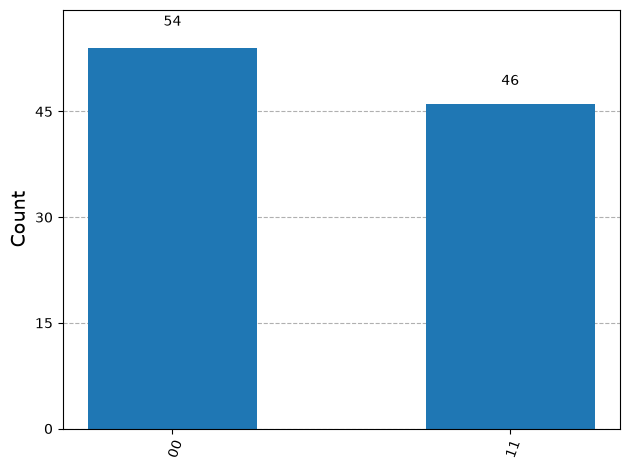

In [2]:
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

simulator = AerSimulator()

job_A = simulator.run(qc_A, shots=100)
result_A = job_A.result()
counts_A = result_A.get_counts()

print("Part A results:", counts_A)

from IPython.display import display
display(plot_histogram(counts_A))

In [3]:
# Part B: Opposite outcomes
qc_B = QuantumCircuit(2, 2)

qc_B.h(0)
qc_B.cx(0, 1)
qc_B.x(1)

qc_B.measure([0, 1], [0, 1])

print(qc_B.draw())

     ┌───┐          ┌─┐   
q_0: ┤ H ├──■───────┤M├───
     └───┘┌─┴─┐┌───┐└╥┘┌─┐
q_1: ─────┤ X ├┤ X ├─╫─┤M├
          └───┘└───┘ ║ └╥┘
c: 2/════════════════╩══╩═
                     0  1 


Part B results: {'10': 53, '01': 47}


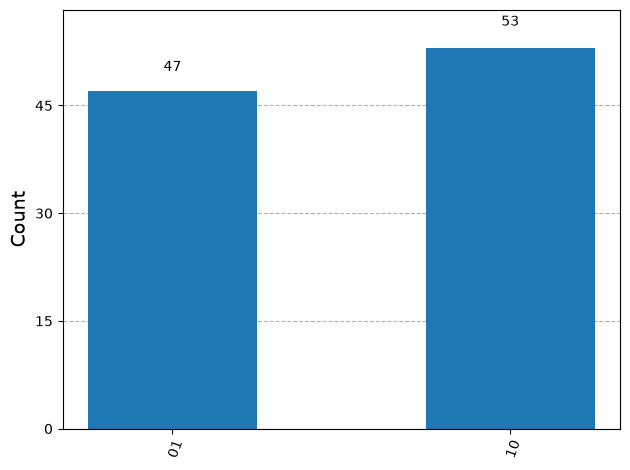

In [4]:
job_B = simulator.run(qc_B, shots=100)
result_B = job_B.result()
counts_B = result_B.get_counts()

print("Part B results:", counts_B)

display(plot_histogram(counts_B))

## Challenge 4: Quantum Correlation Switch

### Predictions

**Part A:** I predicted that `00` and `11` would be the dominant outcomes because the Bell-state circuit produces correlated measurement results.

**Part B:** I predicted that `01` and `10` would be the dominant outcomes because adding an X gate to the second qubit flips its value.

### Results

**Part A — Correlated outcomes**
- `00`: 54 shots
- `11`: 46 shots

**Part B — Opposite outcomes**
- `01`: 47 shots
- `10`: 53 shots

### Comparison

In Part A, the dominant outcomes were `00` and `11`, meaning both qubits had the same measurement value.

In Part B, the dominant outcomes were `01` and `10`, meaning the qubits had opposite measurement values.

### Conclusion

Adding an X gate to the second qubit changes the relationship between the measurement outcomes. The original Bell circuit produces correlated outcomes, while the modified circuit produces opposite outcomes. The results from both experiments agree with my predictions. Only the expected pairs of outcomes appeared in these 100-shot simulations.